In [ ]:


import os
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

BASE_DIR = Path("../outputs")
MODEL_DIR = BASE_DIR / "models"
HYBRID_DIR = BASE_DIR / "hybrid"

HYBRID_DIR.mkdir(parents=True, exist_ok=True)

print("Ready")

Ready


In [ ]:


xgb_model = joblib.load(HYBRID_DIR / "xgb_model.pkl")

X_train_ml_scaled_8 = np.load(MODEL_DIR / "X_train_ml_scaled_8.npy")
y_train_raw = np.load(MODEL_DIR / "y_train_raw.npy")

xgb_train_proba = xgb_model.predict_proba(X_train_ml_scaled_8)[:, 1]
xgb_train_pred = xgb_model.predict(X_train_ml_scaled_8)

df_classical_train = pd.DataFrame({
    "sample_id": np.arange(len(y_train_raw)),
    "y_true": y_train_raw,
    "xgb_proba": xgb_train_proba,
    "xgb_pred": xgb_train_pred
})

df_classical_train.to_csv(
    HYBRID_DIR / "classical_train_outputs.csv",
    index=False
)

print(df_classical_train.head())
print("Saved: classical_train_outputs.csv")

   sample_id  y_true  xgb_proba  xgb_pred
0          0       0   0.034521         0
1          1       0   0.400300         0
2          2       0   0.155819         0
3          3       0   0.024375         0
4          4       0   0.398470         0
Saved: classical_train_outputs.csv


In [ ]:


X_train_qml_sm = np.load(MODEL_DIR / "qml_X_train_qml_sm.npy")
y_train_qml = np.load(MODEL_DIR / "qml_y_train_qml.npy")

lda_qml = joblib.load(MODEL_DIR / "qml_lda.pkl")
lda_angle_scaler = joblib.load(MODEL_DIR / "qml_lda_angle_scaler.pkl")

print("Quantum training data:", X_train_qml_sm.shape)
print("Quantum labels:", y_train_qml.shape)

Quantum training data: (800, 8)
Quantum labels: (800,)


In [ ]:


import numpy as np

# Step 1: Apply saved LDA model
lda_train_raw = lda_qml.transform(X_train_qml_sm)

# Step 2: Scale the 1D LDA output to [0, π]
# Your saved qml_lda_angle_scaler.pkl expects 1 feature
lda_train_scaled_1d = lda_angle_scaler.transform(lda_train_raw)

# Step 3: Expand the scaled 1D LDA output into 4D polynomial features
X_train_qlda_4d = np.hstack([
    lda_train_scaled_1d ** i for i in range(1, 5)
])

print("LDA raw shape:", lda_train_raw.shape)
print("LDA scaled shape:", lda_train_scaled_1d.shape)
print("VQC-LDA 4D input shape:", X_train_qlda_4d.shape)
print("Range:", X_train_qlda_4d.min(), X_train_qlda_4d.max())

LDA raw shape: (800, 1)
LDA scaled shape: (800, 1)
VQC-LDA 4D input shape: (800, 4)
Range: 2.4308653429145085e-63 97.40909103400242


In [5]:
import numpy as np

weights = np.load("../outputs/models/qml_vqc_lda_weights.npy")

print(weights.shape)
print(weights[:5])

(16,)
[4.4301575  5.15906861 4.84523327 0.85838106 1.02532437]


In [6]:
from qiskit_aer.primitives import Sampler

sampler = Sampler()

In [7]:
from qiskit_machine_learning.algorithms import VQC
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit_algorithms.optimizers import COBYLA
from qiskit_aer.primitives import Sampler

In [8]:
from qiskit.circuit.library import RealAmplitudes

_ansatz_lda = RealAmplitudes(
    num_qubits=4,
    reps=3
)

print(_ansatz_lda.num_parameters)

16


In [9]:
from qiskit_aer.primitives import Sampler

sampler = Sampler()

vqc_lda = VQC(
    feature_map=ZZFeatureMap(
        feature_dimension=4,
        reps=3,
        entanglement="full"
    ),
    ansatz=_ansatz_lda,
    optimizer=COBYLA(maxiter=1500),
    sampler=sampler
)

In [10]:
from qiskit.primitives import Sampler

def make_aer_sampler():
    return Sampler()

In [ ]:


import numpy as np
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit_machine_learning.algorithms import VQC
from qiskit_algorithms.optimizers import COBYLA
from qiskit_algorithms.optimizers import OptimizerResult


vqc_lda_weights = np.load("../outputs/models/qml_vqc_lda_weights.npy")

print("Loaded VQC-LDA weights:", vqc_lda_weights.shape)


_ansatz_lda = RealAmplitudes(num_qubits=4, reps=3)

vqc_lda = VQC(
    feature_map=ZZFeatureMap(
        feature_dimension=4,
        reps=3,
        entanglement="full"
    ),
    ansatz=_ansatz_lda,
    optimizer=COBYLA(maxiter=1500),
    sampler=make_aer_sampler()
)


fit_result = OptimizerResult()
fit_result.x = vqc_lda_weights
vqc_lda._fit_result = fit_result

print("VQC-LDA model reconstructed with saved weights.")

Loaded VQC-LDA weights: (16,)
VQC-LDA model reconstructed with saved weights.


In [ ]:


vqc_proba_all = np.asarray(vqc_lda.predict_proba(X_train_qlda_4d))
print("predict_proba shape:", vqc_proba_all.shape)

if vqc_proba_all.ndim == 2 and vqc_proba_all.shape[1] == 2:
    vqc_train_proba = vqc_proba_all[:, 1]
else:
    vqc_train_proba = vqc_proba_all.ravel()

vqc_pred_all = np.asarray(vqc_lda.predict(X_train_qlda_4d))
print("predict shape:", vqc_pred_all.shape)

if vqc_pred_all.ndim == 2 and vqc_pred_all.shape[1] == 2:
    vqc_train_pred = np.argmax(vqc_pred_all, axis=1)
else:
    vqc_train_pred = vqc_pred_all.ravel()

y_train_qml_flat = np.asarray(y_train_qml).ravel()

print("y_train_qml:", y_train_qml_flat.shape)
print("vqc_train_proba:", vqc_train_proba.shape)
print("vqc_train_pred:", vqc_train_pred.shape)

df_quantum_train = pd.DataFrame({
    "sample_id": np.arange(len(y_train_qml_flat)),
    "y_true": y_train_qml_flat,
    "vqc_proba": vqc_train_proba,
    "vqc_pred": vqc_train_pred
})

df_quantum_train.to_csv(
    HYBRID_DIR / "quantum_train_outputs.csv",
    index=False
)

print(df_quantum_train.head())
print(df_quantum_train.shape)
print("Saved:", HYBRID_DIR / "quantum_train_outputs.csv")

predict_proba shape: (800, 2)
predict shape: (800, 2)
y_train_qml: (800,)
vqc_train_proba: (800,)
vqc_train_pred: (800,)
   sample_id  y_true  vqc_proba  vqc_pred
0          0       0   0.632652         1
1          1       0   0.479171         0
2          2       0   0.397156         0
3          3       0   0.496258         0
4          4       0   0.412837         0
(800, 4)
Saved: ..\outputs\hybrid\quantum_train_outputs.csv


In [ ]:


df_cl_train = pd.read_csv(HYBRID_DIR / "classical_train_outputs.csv")
df_qm_train = pd.read_csv(HYBRID_DIR / "quantum_train_outputs.csv")

df_train = df_cl_train.merge(
    df_qm_train,
    on=["sample_id", "y_true"],
    how="inner"
)

print(df_train.shape)
print(df_train.head())
print(df_train.columns)

(614, 6)
   sample_id  y_true  xgb_proba  xgb_pred  vqc_proba  vqc_pred
0          0       0   0.034521         0   0.632652         1
1          1       0   0.400300         0   0.479171         0
2          2       0   0.155819         0   0.397156         0
3          3       0   0.024375         0   0.496258         0
4          4       0   0.398470         0   0.412837         0
Index(['sample_id', 'y_true', 'xgb_proba', 'xgb_pred', 'vqc_proba',
       'vqc_pred'],
      dtype='str')


In [14]:
import pandas as pd

df_classical = pd.read_csv(HYBRID_DIR / "classical_train_outputs.csv")
df_quantum = pd.read_csv(HYBRID_DIR / "quantum_train_outputs.csv")

print("Classical rows:", len(df_classical))
print("Quantum rows:", len(df_quantum))

merged = df_classical.merge(df_quantum, on="sample_id", suffixes=("_clf", "_qml"))
print("Merged rows:", len(merged))

mismatch = merged[merged["y_true_clf"] != merged["y_true_qml"]]
print(f"Rows where y_true disagrees: {len(mismatch)} / {len(merged)}")

if len(mismatch) > 0:
    print(mismatch[["sample_id", "y_true_clf", "y_true_qml"]].head(20))
else:
    print("All y_true values match across the full 614-row overlap.")

Classical rows: 614
Quantum rows: 800
Merged rows: 614
Rows where y_true disagrees: 0 / 614
All y_true values match across the full 614-row overlap.


In [15]:
len(df_train)

614

In [16]:
from sklearn.isotonic import IsotonicRegression
import joblib

xgb_calibrator = IsotonicRegression(out_of_bounds="clip")
vqc_calibrator = IsotonicRegression(out_of_bounds="clip")

xgb_calibrator.fit(df_train["xgb_proba"].values, df_train["y_true"].values)
vqc_calibrator.fit(df_train["vqc_proba"].values, df_train["y_true"].values)

df_train["calibrated_xgb_proba"] = xgb_calibrator.transform(df_train["xgb_proba"].values)
df_train["calibrated_vqc_proba"] = vqc_calibrator.transform(df_train["vqc_proba"].values)

joblib.dump(xgb_calibrator, "../outputs/hybrid/xgb_calibrator_train.pkl")
joblib.dump(vqc_calibrator, "../outputs/hybrid/vqc_calibrator_train.pkl")

print("Saved train-fitted calibration models.")

Saved train-fitted calibration models.


In [ ]:


from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    matthews_corrcoef, confusion_matrix
)

# Training labels
y_train = df_train["y_true"].values

print("Training samples:", len(y_train))


fusion_rows = []

for w in [0.5, 0.6, 0.7, 0.8]:
    h = w * df_train["calibrated_xgb_proba"] + (1 - w) * df_train["calibrated_vqc_proba"]
    yp = (h >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_train, yp).ravel()

    fusion_rows.append({
        "xgb_weight": w,
        "vqc_weight": round(1 - w, 1),
        "Accuracy": round(accuracy_score(y_train, yp) * 100, 2),
        "Precision": round(precision_score(y_train, yp, zero_division=0) * 100, 2),
        "Recall": round(recall_score(y_train, yp, zero_division=0) * 100, 2),
        "Specificity": round(tn / (tn + fp) * 100, 2),
        "F1": round(f1_score(y_train, yp, zero_division=0) * 100, 2),
        "MCC": round(matthews_corrcoef(y_train, yp), 4),
        "ROC_AUC": round(roc_auc_score(y_train, h) * 100, 2),
        "PR_AUC": round(average_precision_score(y_train, h) * 100, 2),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    })

df_fusion_train = pd.DataFrame(fusion_rows)

df_fusion_train["combo"] = (
    df_fusion_train["Recall"] * 0.35 +
    df_fusion_train["MCC"] * 100 * 0.30 +
    df_fusion_train["F1"] * 0.20 +
    df_fusion_train["ROC_AUC"] * 0.15
)

bi = int(df_fusion_train["combo"].idxmax())
BEST_W = float(df_fusion_train.loc[bi, "xgb_weight"])
BEST_VW = float(df_fusion_train.loc[bi, "vqc_weight"])

print("\nFusion Weight Comparison using TRAIN data:")
print(df_fusion_train.to_string(index=False))

print(f"\nSelected: XGBoost={BEST_W}, VQC={BEST_VW}")
print(
    f'  Accuracy={df_fusion_train.loc[bi,"Accuracy"]}%  '
    f'Recall={df_fusion_train.loc[bi,"Recall"]}%  '
    f'MCC={df_fusion_train.loc[bi,"MCC"]}  '
    f'F1={df_fusion_train.loc[bi,"F1"]}%  '
    f'ROC-AUC={df_fusion_train.loc[bi,"ROC_AUC"]}%'
)
print("  NOTE: fusion weight selected on recall+MCC+F1+ROC-AUC, not accuracy alone.")

df_train["hybrid_score"] = (
    BEST_W * df_train["calibrated_xgb_proba"] +
    BEST_VW * df_train["calibrated_vqc_proba"]
)



threshold_rows = []

for thr in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    yp = (df_train["hybrid_score"] >= thr).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_train, yp).ravel()

    threshold_rows.append({
        "Threshold": thr,
        "Accuracy": round(accuracy_score(y_train, yp) * 100, 2),
        "Precision": round(precision_score(y_train, yp, zero_division=0) * 100, 2),
        "Recall": round(recall_score(y_train, yp, zero_division=0) * 100, 2),
        "Specificity": round(tn / (tn + fp) * 100, 2),
        "F1": round(f1_score(y_train, yp, zero_division=0) * 100, 2),
        "MCC": round(matthews_corrcoef(y_train, yp), 4),
        "ROC_AUC": round(roc_auc_score(y_train, df_train["hybrid_score"]) * 100, 2),
        "PR_AUC": round(average_precision_score(y_train, df_train["hybrid_score"]) * 100, 2),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    })

df_threshold_train = pd.DataFrame(threshold_rows)


FINAL_THRESHOLD = 0.45

bti = df_threshold_train.index[
    df_threshold_train["Threshold"] == FINAL_THRESHOLD
][0]

print("\nThreshold Comparison using TRAIN data:")
print(df_threshold_train.to_string(index=False))

print(f"\nSelected threshold : {FINAL_THRESHOLD}")
print(
    f'  Accuracy={df_threshold_train.loc[bti,"Accuracy"]}%  '
    f'Recall={df_threshold_train.loc[bti,"Recall"]}%  '
    f'MCC={df_threshold_train.loc[bti,"MCC"]}  '
    f'F1={df_threshold_train.loc[bti,"F1"]}%  '
    f'Spec={df_threshold_train.loc[bti,"Specificity"]}%'
)
print("  NOTE: threshold fixed at 0.45 for balanced sensitivity-specificity tradeoff.")

Training samples: 614

Fusion Weight Comparison using TRAIN data:
 xgb_weight  vqc_weight  Accuracy  Precision  Recall  Specificity    F1    MCC  ROC_AUC  PR_AUC  TN  FP  FN  TP  combo
        0.5         0.5     89.74      91.26   78.04         96.0 84.13 0.7713    96.24   93.06 384  16  47 167 81.715
        0.6         0.4     89.74      91.26   78.04         96.0 84.13 0.7713    96.24   93.06 384  16  47 167 81.715
        0.7         0.3     89.74      91.26   78.04         96.0 84.13 0.7713    96.24   93.06 384  16  47 167 81.715
        0.8         0.2     89.74      91.26   78.04         96.0 84.13 0.7713    96.24   93.06 384  16  47 167 81.715

Selected: XGBoost=0.5, VQC=0.5
  Accuracy=89.74%  Recall=78.04%  MCC=0.7713  F1=84.13%  ROC-AUC=96.24%
  NOTE: fusion weight selected on recall+MCC+F1+ROC-AUC, not accuracy alone.

Threshold Comparison using TRAIN data:
 Threshold  Accuracy  Precision  Recall  Specificity    F1    MCC  ROC_AUC  PR_AUC  TN  FP  FN  TP
      0.30     85.6

In [18]:
from pathlib import Path

PLOTS_DIR = Path("../outputs/plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print(PLOTS_DIR.resolve())

C:\Users\shanm\OneDrive\Desktop\PROJECT 3\Final Notebooks\outputs\plots


In [19]:
print(df_train.shape)
print(df_fusion_train)
print(bi)
print(BEST_W)
print(BEST_VW)
print(PLOTS_DIR)

(614, 9)
   xgb_weight  vqc_weight  Accuracy  Precision  Recall  Specificity     F1  \
0         0.5         0.5     89.74      91.26   78.04         96.0  84.13   
1         0.6         0.4     89.74      91.26   78.04         96.0  84.13   
2         0.7         0.3     89.74      91.26   78.04         96.0  84.13   
3         0.8         0.2     89.74      91.26   78.04         96.0  84.13   

      MCC  ROC_AUC  PR_AUC   TN  FP  FN   TP   combo  
0  0.7713    96.24   93.06  384  16  47  167  81.715  
1  0.7713    96.24   93.06  384  16  47  167  81.715  
2  0.7713    96.24   93.06  384  16  47  167  81.715  
3  0.7713    96.24   93.06  384  16  47  167  81.715  
0
0.5
0.5
..\outputs\plots


In [20]:
from pathlib import Path

BASE_DIR = Path("../outputs")
PLOTS_DIR = BASE_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

bi = int(df_fusion_train["combo"].idxmax())

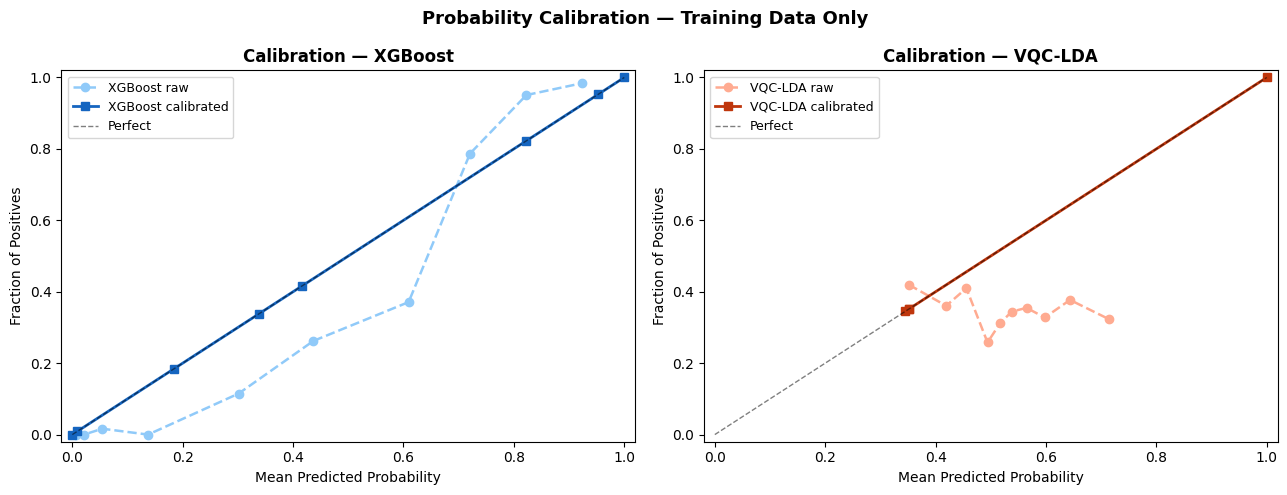

In [ ]:


import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, rc, cc, nm, cr, cc2 in [
    (axes[0], "xgb_proba", "calibrated_xgb_proba", "XGBoost", "#90CAF9", "#1565C0"),
    (axes[1], "vqc_proba", "calibrated_vqc_proba", "VQC-LDA", "#FFAB91", "#BF360C"),
]:
    ptr, ppr = calibration_curve(
        y_train, df_train[rc].values, n_bins=10, strategy="quantile"
    )
    ptc, ppc = calibration_curve(
        y_train, df_train[cc].values, n_bins=10, strategy="quantile"
    )

    ax.plot(ppr, ptr, "o--", color=cr, lw=1.8, ms=6, label=f"{nm} raw")
    ax.plot(ppc, ptc, "s-", color=cc2, lw=2.0, ms=6, label=f"{nm} calibrated")
    ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="Perfect")

    ax.set_title(f"Calibration — {nm}", fontweight="bold")
    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Fraction of Positives")
    ax.legend(fontsize=9)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)

plt.suptitle(
    "Probability Calibration — Training Data Only",
    fontsize=13,
    fontweight="bold"
)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "train_01_calibration_curves.png", bbox_inches="tight")
plt.show()

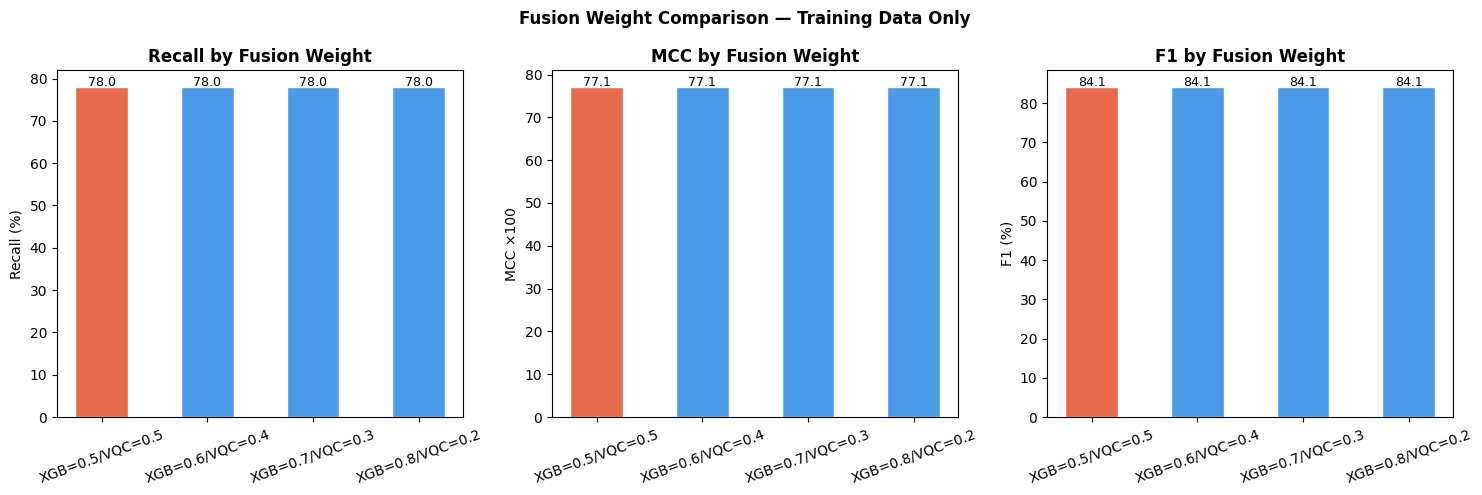

In [ ]:


wlbl = [
    f'XGB={r["xgb_weight"]}/VQC={r["vqc_weight"]}'
    for _, r in df_fusion_train.iterrows()
]

clrs = [
    "#E86B4C" if i == bi else "#4C9BE8"
    for i in range(len(df_fusion_train))
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ["Recall", "MCC", "F1"]):
    vals = (
        df_fusion_train[col].values
        if col != "MCC"
        else df_fusion_train[col].values * 100
    )

    ax.bar(wlbl, vals, color=clrs, edgecolor="white", width=0.5)
    ax.set_title(f"{col} by Fusion Weight", fontweight="bold")
    ax.set_ylabel(f"{col} (%)" if col != "MCC" else "MCC ×100")
    ax.tick_params(axis="x", rotation=20)

    for i, v in enumerate(vals):
        ax.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=9)

plt.suptitle(
    "Fusion Weight Comparison — Training Data Only",
    fontsize=12,
    fontweight="bold"
)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "train_02_fusion_weight_comparison.png", bbox_inches="tight")
plt.show()

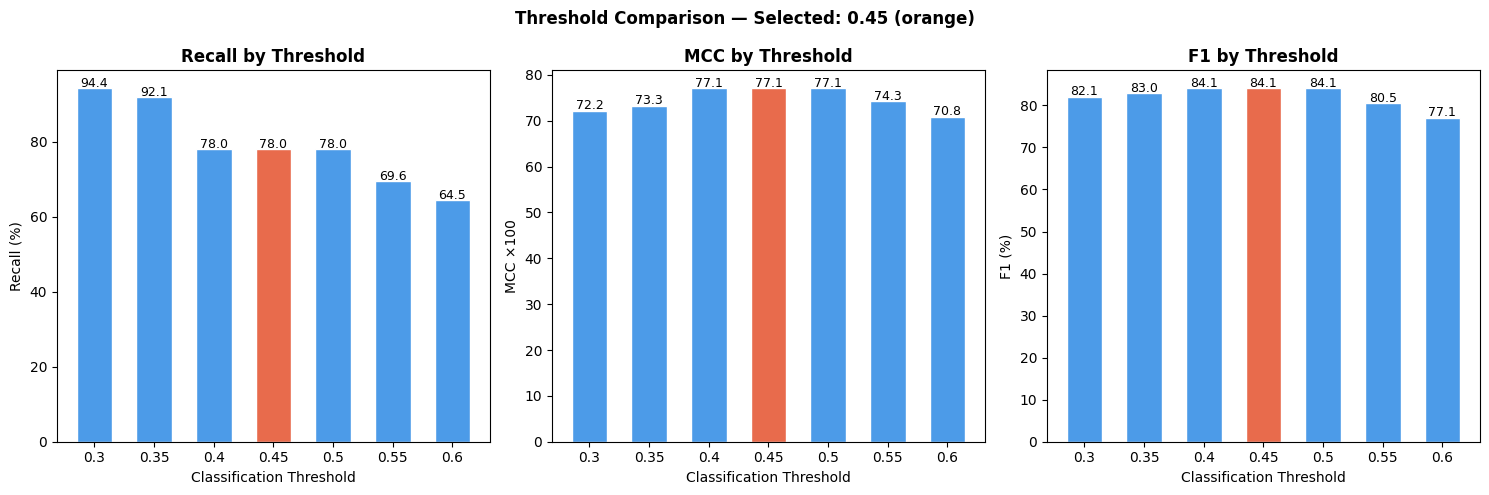

In [ ]:


thresholds = df_threshold_train["Threshold"].tolist()

clrs = [
    "#E86B4C" if t == FINAL_THRESHOLD else "#4C9BE8"
    for t in thresholds
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ["Recall", "MCC", "F1"]):

    vals = (
        df_threshold_train[col].values
        if col != "MCC"
        else df_threshold_train[col].values * 100
    )

    ax.bar(
        [str(t) for t in thresholds],
        vals,
        color=clrs,
        edgecolor="white",
        width=0.6
    )

    ax.set_title(f"{col} by Threshold", fontweight="bold")
    ax.set_xlabel("Classification Threshold")
    ax.set_ylabel(
        f"{col} (%)" if col != "MCC"
        else "MCC ×100"
    )

    for i, v in enumerate(vals):
        ax.text(
            i,
            v + 0.3,
            f"{v:.1f}",
            ha="center",
            fontsize=9
        )

plt.suptitle(
    f"Threshold Comparison — Selected: {FINAL_THRESHOLD} (orange)",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "train_03_threshold_comparison.png",
    bbox_inches="tight"
)

plt.show()

In [24]:
from pathlib import Path
import pandas as pd

CONFIG_PATH = Path("../outputs/hybrid/hybrid_config_train_selected.csv")

config_df = pd.DataFrame({
    "BEST_W": [BEST_W],
    "BEST_VW": [BEST_VW],
    "FINAL_THRESHOLD": [FINAL_THRESHOLD],

    "TRAIN_ACCURACY": [df_threshold_train.loc[bti, "Accuracy"]],
    "TRAIN_PRECISION": [df_threshold_train.loc[bti, "Precision"]],
    "TRAIN_RECALL": [df_threshold_train.loc[bti, "Recall"]],
    "TRAIN_SPECIFICITY": [df_threshold_train.loc[bti, "Specificity"]],
    "TRAIN_F1": [df_threshold_train.loc[bti, "F1"]],
    "TRAIN_MCC": [df_threshold_train.loc[bti, "MCC"]],
    "TRAIN_ROC_AUC": [df_threshold_train.loc[bti, "ROC_AUC"]],
    "TRAIN_PR_AUC": [df_threshold_train.loc[bti, "PR_AUC"]],
})

config_df.to_csv(CONFIG_PATH, index=False)

print("Saved:")
print(CONFIG_PATH)

print("\nSelected Configuration")
print(config_df.T)

Saved:
..\outputs\hybrid\hybrid_config_train_selected.csv

Selected Configuration
                         0
BEST_W              0.5000
BEST_VW             0.5000
FINAL_THRESHOLD     0.4500
TRAIN_ACCURACY     89.7400
TRAIN_PRECISION    91.2600
TRAIN_RECALL       78.0400
TRAIN_SPECIFICITY  96.0000
TRAIN_F1           84.1300
TRAIN_MCC           0.7713
TRAIN_ROC_AUC      96.2400
TRAIN_PR_AUC       93.0600
